# Loanliness: data pipeline, balancing, clustering and visualisation

Reimplementation of the preprocessing / k-means / PCA + t-SNE parts of the paper. Sections follow the task list:
1. joined feature table, 2. cleaning, 3. encoding and scaling, 4. split, 5. balancing, 6. polynomial features, 7. k-means + per-cluster LightGBM, 8. PCA / t-SNE.

## 1. Build the joined feature table

In [1]:
import gc, json, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

DATA = Path("dataset")
OUT = Path("artifacts")
OUT.mkdir(exist_ok=True)

CONFIG = {
    "seed": 42,
    "test_size": 0.2,
    "missing_col_thresh": 0.30,   # drop columns with more than this fraction missing
    "impute_mode": "mean",        # "mean": fill with train means (keep all rows), "drop_rows": paper-style
    "drop_ext_source": True,      # the paper leaves EXT_SOURCE_1..3 out (section III-A, and the authors' code drops them)
    "cat_label_max_card": 2,      # categoricals with <= this many levels are label encoded, rest one-hot
}

In [2]:
def agg_table(df, key, prefix, drop_cols=()):
    # numeric -> mean/min/max/sum, categorical -> one-hot then mean (share) and sum (count)
    df = df.drop(columns=list(drop_cols), errors="ignore")
    cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c != key]
    num = df.drop(columns=cat_cols)
    num_cols = [c for c in num.columns if c != key]
    parts = [num.groupby(key)[num_cols].agg(["mean", "min", "max", "sum"])]
    if cat_cols:
        dummies = pd.get_dummies(df[cat_cols], dtype="float32", dummy_na=False)
        dummies[key] = df[key].values
        parts.append(dummies.groupby(key).agg(["mean", "sum"]))
    out = pd.concat(parts, axis=1)
    out.columns = [f"{prefix}_{a}_{b}".replace(" ", "_") for a, b in out.columns]
    out[f"{prefix}_COUNT"] = df.groupby(key).size().astype("float32")
    return out.astype("float32")


def read(name, **kw):
    df = pd.read_csv(DATA / name, **kw)
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")
    return df

In [3]:
# bureau_balance -> per bureau record -> merged into bureau -> per client
bb = read("bureau_balance.csv")
bb_agg = agg_table(bb, "SK_ID_BUREAU", "bb")
del bb; gc.collect()

bureau = read("bureau.csv")
bureau = bureau.merge(bb_agg, left_on="SK_ID_BUREAU", right_index=True, how="left")
bureau_agg = agg_table(bureau, "SK_ID_CURR", "bureau", drop_cols=["SK_ID_BUREAU"])
del bureau, bb_agg; gc.collect()
bureau_agg.shape

(305811, 179)

In [4]:
# previous_application: 365243 is a sentinel in the DAYS_* columns here too
prev = read("previous_application.csv")
day_cols = [c for c in prev.columns if c.startswith("DAYS_")]
prev[day_cols] = prev[day_cols].replace(365243, np.nan)
prev_agg = agg_table(prev, "SK_ID_CURR", "prev", drop_cols=["SK_ID_PREV"])
del prev; gc.collect()

pos = read("POS_CASH_balance.csv")
pos_agg = agg_table(pos, "SK_ID_CURR", "pos", drop_cols=["SK_ID_PREV"])
pos_agg["pos_N_LOANS"] = pos.groupby("SK_ID_CURR")["SK_ID_PREV"].nunique().astype("float32")
del pos; gc.collect()

inst = read("installments_payments.csv")
inst["DAYS_PAST_DUE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]   # >0 means paid late
inst["PAYMENT_DIFF"] = inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]            # >0 means underpaid
inst_agg = agg_table(inst, "SK_ID_CURR", "inst", drop_cols=["SK_ID_PREV"])
del inst; gc.collect()

cc = read("credit_card_balance.csv")
cc_agg = agg_table(cc, "SK_ID_CURR", "cc", drop_cols=["SK_ID_PREV"])
del cc; gc.collect()
[t.shape for t in (prev_agg, pos_agg, inst_agg, cc_agg)]

[(338857, 363), (337252, 40), (339587, 33), (103558, 95)]

In [5]:
# left join everything onto application_train
app = read("application_train.csv")
app = app.rename(columns={c: f"app_{c}" for c in app.columns if c not in ("SK_ID_CURR", "TARGET")})
df = app
for agg in (bureau_agg, prev_agg, pos_agg, inst_agg, cc_agg):
    df = df.merge(agg, left_on="SK_ID_CURR", right_index=True, how="left")
del app, bureau_agg, prev_agg, pos_agg, inst_agg, cc_agg; gc.collect()

assert len(df) == 307511 and df["SK_ID_CURR"].is_unique
print(df.shape, "| default rate:", df["TARGET"].mean().round(4))
df.columns.to_series().str.split("_").str[0].value_counts()

(307511, 832) | default rate: 0.0807


prev      363
bureau    179
app       120
cc         95
pos        40
inst       33
SK          1
TARGET      1
Name: count, dtype: int64

## 2. Clean invalid and missing values and split

Only stateless fixes happen before the split. The split itself (stratified, fixed seed) is the contract with Person B (saved in section 4); it has to come before anything that learns from the data, so it sits here. The column-drop rule and the imputer are fitted on the train split only.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# DAYS_EMPLOYED == 365243 is a placeholder (~18% of clients), not a real value
df["app_DAYS_EMPLOYED_ANOM"] = (df["app_DAYS_EMPLOYED"] == 365243).astype("float32")
df["app_DAYS_EMPLOYED"] = df["app_DAYS_EMPLOYED"].replace(365243, np.nan)

# a client with no bureau/card/... records has NaN everywhere for that source; the count columns are really 0
count_cols = [c for c in df.columns if c.endswith(("_COUNT", "_N_LOANS"))]
df[count_cols] = df[count_cols].fillna(0)

ids = df["SK_ID_CURR"]
y = df["TARGET"].astype("int8")
X = df.drop(columns=["SK_ID_CURR", "TARGET"])
if CONFIG["drop_ext_source"]:
    X = X.drop(columns=[c for c in X.columns if "EXT_SOURCE" in c])
for c in X.select_dtypes(exclude="number").columns:
    X[c] = X[c].astype(object)
del df; gc.collect()

# stratified split before any fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=CONFIG["test_size"], stratify=y, random_state=CONFIG["seed"])
del X; gc.collect()
print(X_train.shape, X_test.shape, y_train.mean().round(4), y_test.mean().round(4))

(246008, 828) (61503, 828) 0.0807 0.0807


In [7]:
# drop columns with >30% missing (rate measured on train only)
miss = X_train.isna().mean()
drop_cols = miss[miss > CONFIG["missing_col_thresh"]].index.tolist()
print(f"dropping {len(drop_cols)} of {X_train.shape[1]} columns")
print(pd.Series(drop_cols).str.split("_").str[0].value_counts().to_dict())

keep_cols = [c for c in X_train.columns if c not in drop_cols]
X_train, X_test = X_train[keep_cols], X_test[keep_cols]

dropping 221 of 828 columns
{'cc': 94, 'bureau': 69, 'app': 49, 'prev': 9}


In [8]:
num_cols = X_train.select_dtypes("number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

if CONFIG["impute_mode"] == "drop_rows":
    # paper style: remove any row with a missing value (no learning involved, so both splits are treated alike)
    keep_tr, keep_te = ~X_train.isna().any(axis=1), ~X_test.isna().any(axis=1)
    X_train, y_train = X_train[keep_tr], y_train[keep_tr]
    X_test, y_test = X_test[keep_te], y_test[keep_te]

# numeric -> train mean, categorical -> explicit "missing" level; fitted on train only
imputer = ColumnTransformer([
    ("num", SimpleImputer(strategy="mean"), num_cols),
    ("cat", SimpleImputer(strategy="constant", fill_value="missing"), cat_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)
X_train_imp[num_cols] = X_train_imp[num_cols].astype("float32")
X_test_imp[num_cols] = X_test_imp[num_cols].astype("float32")
assert not X_train_imp.isna().any().any() and not X_test_imp.isna().any().any()
print(X_train_imp.shape, X_test_imp.shape)

(246008, 607) (61503, 607)


In [9]:
# row cost of the paper's drop-rows strategy on the same columns, for the write-up
n_complete = int((~pd.concat([X_train, X_test]).isna().any(axis=1)).sum()) if CONFIG["impute_mode"] == "mean" else len(X_train) + len(X_test)
print(f"rows kept with mean imputation: {len(y_train) + len(y_test):,}")
print(f"rows that would survive drop-rows: {n_complete:,} ({n_complete / len(y):.1%})")

rows kept with mean imputation: 307,511
rows that would survive drop-rows: 148,536 (48.3%)


## 3. Encode and scale

Binary / low-cardinality categoricals are label encoded, the rest one-hot encoded. Numeric columns are min-max scaled to [0, 1], as in the authors' code, so every feature ends up on the 0 to 1 range. Everything is fitted on train.

In [10]:
import re
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler

card = X_train_imp[cat_cols].nunique()
label_cols = card[card <= CONFIG["cat_label_max_card"]].index.tolist()
onehot_cols = card[card > CONFIG["cat_label_max_card"]].index.tolist()
print(len(label_cols), "label encoded,", len(onehot_cols), "one-hot encoded")

encoder = ColumnTransformer([
    ("label", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype="float32"), label_cols),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype="float32"), onehot_cols),
    ("num", "passthrough", num_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train_enc = encoder.fit_transform(X_train_imp)
X_test_enc = encoder.transform(X_test_imp)

# min-max scale the numeric columns; label/one-hot outputs are already 0/1, so all features share the [0, 1] range
scaler = ColumnTransformer([("num", MinMaxScaler(), num_cols)],
                           remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
X_train_s = scaler.fit_transform(X_train_enc).astype("float32")
X_test_s = scaler.transform(X_test_enc).astype("float32")
raw_names = X_train_s.columns.tolist()
# LightGBM rejects special characters (spaces/commas from category levels), so use clean names everywhere
feature_names = [re.sub(r"[^0-9a-zA-Z_]", "_", n) for n in raw_names]
assert len(set(feature_names)) == len(feature_names)
X_train_s.columns = X_test_s.columns = feature_names
del X_train_enc, X_test_enc; gc.collect()
print(X_train_s.shape, X_test_s.shape)

3 label encoded, 8 one-hot encoded


(246008, 700) (61503, 700)


In [11]:
# everything needed to push new raw data (same columns as the joined table) through the same pipeline
joblib.dump({"keep_cols": keep_cols, "imputer": imputer, "encoder": encoder, "scaler": scaler,
             "raw_names": raw_names, "feature_names": feature_names, "config": CONFIG}, OUT / "preprocessor.joblib")

def transform_new(raw: pd.DataFrame) -> pd.DataFrame:
    # raw: joined features after the DAYS_EMPLOYED fix and count-fill above, without ID/TARGET columns
    art = joblib.load(OUT / "preprocessor.joblib")
    x = raw[art["keep_cols"]]
    out = art["scaler"].transform(art["encoder"].transform(art["imputer"].transform(x)))[art["raw_names"]]
    out.columns = art["feature_names"]
    return out

# sanity check: reloaded pipeline reproduces the test matrix
assert np.allclose(transform_new(X_test.iloc[:200]).to_numpy(), X_test_s.iloc[:200].to_numpy(), atol=1e-4)

## 4. Save the splits and data dictionary

The split was made in section 2 (stratified, `seed` from `CONFIG`) before any fitting. Both splits are saved with `SK_ID_CURR` and `TARGET` in front of the feature columns, in a fixed column order recorded in `schema.json`.

In [12]:
def with_ids(Xs, ys):
    out = Xs.copy()
    out.insert(0, "TARGET", ys.to_numpy())
    out.insert(0, "SK_ID_CURR", ids.loc[Xs.index].to_numpy())
    return out.reset_index(drop=True)

train_out, test_out = with_ids(X_train_s, y_train), with_ids(X_test_s, y_test)
train_out.to_parquet(OUT / "train.parquet")
test_out.to_parquet(OUT / "test.parquet")
json.dump({"id": "SK_ID_CURR", "target": "TARGET", "features": feature_names, "config": CONFIG},
          open(OUT / "schema.json", "w"), indent=1)
print(train_out.shape, test_out.shape)

(246008, 702) (61503, 702)


In [13]:
# data dictionary: feature -> source file, encoding, and the original description where one exists
src_map = {"app": "application_train", "bureau": "bureau", "prev": "previous_application",
           "pos": "POS_CASH_balance", "inst": "installments_payments", "cc": "credit_card_balance"}
desc = pd.read_csv(DATA / "HomeCredit_columns_description.csv", encoding="latin-1")
desc = desc[desc["Table"].str.startswith("application")].set_index("Row")["Description"].to_dict()

def describe(f):
    prefix = f.split("_")[0]
    if f.startswith("bureau_bb_"):
        src = "bureau_balance (via bureau)"
    else:
        src = src_map.get(prefix, "derived")
    kind = ("label" if any(f == c for c in label_cols) else
            "one-hot" if any(f.startswith(c + "_") for c in onehot_cols) else "numeric")
    base = f[4:] if prefix == "app" else ""
    d = desc.get(base) or desc.get(base.rsplit("_", 1)[0], "") if base else ""
    if f == "app_DAYS_EMPLOYED_ANOM": d, src = "1 if DAYS_EMPLOYED was the 365243 placeholder", "application_train (derived)"
    return src, kind, d

dictionary = pd.DataFrame([(f, *describe(f)) for f in feature_names], columns=["feature", "source", "encoding", "description"])
dictionary.to_csv(OUT / "data_dictionary.csv", index=False)
dictionary.groupby(["source", "encoding"]).size()

source                       encoding
POS_CASH_balance             numeric      40
application_train            label         3
                             numeric      57
                             one-hot     101
application_train (derived)  numeric       1
bureau                       numeric      89
bureau_balance (via bureau)  numeric      21
credit_card_balance          numeric       1
installments_payments        numeric      33
previous_application         numeric     354
dtype: int64

## 5. Balancing utilities

All three act on the training set only. The authors' code tests on one fifth of the positives plus the same number of negatives, and trains on the remaining positives plus as many negatives. Our stratified 20% test already holds one fifth of the positives, so down-sampling each split gives the same construction (`X_train_bal`, `X_test_bal`). Results at the natural class ratio are kept next to it for reference.

In [14]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
import lightgbm as lgb


def downsample(X, y, seed=CONFIG["seed"]):
    # keep every positive, sample the same number of negatives
    pos = y.index[y == 1]
    neg = y.index[y == 0].to_series().sample(len(pos), random_state=seed).index
    idx = pos.union(neg)
    idx = pd.Index(np.random.default_rng(seed).permutation(idx))
    return X.loc[idx], y.loc[idx]


def smote(X, y, seed=CONFIG["seed"]):
    # needs imputed, encoded numeric input
    Xr, yr = SMOTE(random_state=seed).fit_resample(X, y)
    return pd.DataFrame(Xr, columns=X.columns).astype("float32"), pd.Series(yr, name=y.name)


def class_weights(y):
    # w_i = n / (2 n_i)
    n = len(y)
    return {int(c): n / (2 * k) for c, k in y.value_counts().items()}


w = class_weights(y_train)
json.dump(w, open(OUT / "class_weights.json", "w"))
print("class weights:", w)

class weights: {0: 0.5439092983356032, 1: 6.193554884189325}


In [15]:
# stand-ins for Person B's model code: a LightGBM and a logistic regression fit + the paper's metric layout
def fit_lgbm(X, y, class_weight=None):
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight=class_weight,
                           random_state=CONFIG["seed"], n_jobs=-1, verbose=-1)
    return m.fit(X, y)


def fit_lr(X, y, class_weight=None):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=300, class_weight=class_weight)).fit(X, y)


def metrics(y_true, y_pred, y_prob=None):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "prec_0": p[0], "prec_1": p[1],
           "rec_0": r[0], "rec_1": r[1], "f1_0": f[0], "f1_1": f[1], "n": len(y_true), "pos_rate": float(np.mean(y_true))}
    if y_prob is not None and len(np.unique(y_true)) == 2:
        out["auc"] = roc_auc_score(y_true, y_prob)
    return out

# paper protocol: balanced train and balanced test
X_train_bal, y_train_bal = downsample(X_train_s, y_train)
X_test_bal, y_test_bal = downsample(X_test_s, y_test)
print("balanced train:", X_train_bal.shape, y_train_bal.mean(), "| balanced test:", X_test_bal.shape, y_test_bal.mean())

X_smote, y_smote = smote(X_train_s, y_train)
setups = {
    "none": (X_train_s, y_train, None),
    "down-sampling": (X_train_bal, y_train_bal, None),
    "SMOTE": (X_smote, y_smote, None),
    "class weights": (X_train_s, y_train, w),
}
rows, fitted = [], {}
for mname, fit in {"LightGBM": fit_lgbm, "LogReg": fit_lr}.items():
    for name, (Xb, yb, cw) in setups.items():
        m = fitted[mname, name] = fit(Xb, yb, cw)
        for tname, (Xt, yt) in {"natural": (X_test_s, y_test), "balanced": (X_test_bal, y_test_bal)}.items():
            rows.append({"model": mname, "train": name, "test": tname, "n_train": len(yb),
                         **metrics(yt, m.predict(Xt), m.predict_proba(Xt)[:, 1])})
pd.DataFrame(rows).set_index(["model", "train", "test"]).round(3)

balanced train: (39720, 700) 0.5 | balanced test: (9930, 700) 0.5


n_train  accuracy  prec_0  prec_1  rec_0  \
model    train         test                                                 
LightGBM none          natural    246008     0.920   0.921   0.611  0.999   
                       balanced   246008     0.511   0.506   0.929  0.998   
         down-sampling natural     39720     0.689   0.962   0.163  0.689   
                       balanced    39720     0.688   0.689   0.686  0.683   
         SMOTE         natural    452296     0.919   0.921   0.512  0.998   
                       balanced   452296     0.510   0.505   0.938  0.999   
         class weights natural    246008     0.725   0.961   0.178  0.731   
                       balanced   246008     0.692   0.681   0.704  0.721   
LogReg   none          natural    246008     0.919   0.920   0.433  0.998   
                       balanced   246008     0.506   0.503   0.890  0.998   
         down-sampling natural     39720     0.677   0.961   0.157  0.676   
                       balanced    39720     0.681   0.683   0.679  0.675   
         SMOTE         natural    452296     0.690   0.956   0.155  0.695   
                       balanced   452296     0.666   0.657   0.677  0.695   
         class weights natural    246008     0.681   0.961   0.158  0.681   
                       balanced   246008     0.682   0.682   0.683  0.683   

                                 rec_1   f1_0   f1_1      n  pos_rate    auc  
model    train         test                                                   
LightGBM none          natural   0.024  0.958  0.046  61503     0.081  0.761  
                       balanced  0.024  0.671  0.046   9930     0.500  0.757  
         down-sampling natural   0.692  0.803  0.264  61503     0.081  0.756  
                       balanced  0.692  0.686  0.689   9930     0.500  0.753  
         SMOTE         natural   0.021  0.958  0.041  61503     0.081  0.755  
                       balanced  0.021  0.671  0.041   9930     0.500  0.754  
         class weights natural   0.663  0.830  0.280  61503     0.081  0.762  
                       balanced  0.663  0.701  0.683   9930     0.500  0.758  
LogReg   none          natural   0.013  0.958  0.025  61503     0.081  0.744  
                       balanced  0.013  0.669  0.026   9930     0.500  0.742  
         down-sampling natural   0.687  0.794  0.256  61503     0.081  0.741  
                       balanced  0.687  0.679  0.683   9930     0.500  0.739  
         SMOTE         natural   0.638  0.805  0.249  61503     0.081  0.729  
                       balanced  0.638  0.676  0.657   9930     0.500  0.728  
         class weights natural   0.682  0.797  0.257  61503     0.081  0.744  
                       balanced  0.682  0.683  0.682   9930     0.500  0.742

In [16]:
# why SMOTE does nothing for the tree model: synthetic rows are recognisable, so "looks synthetic" becomes the positive rule
n_real = len(X_train_s)
m = fitted["LightGBM", "SMOTE"]
print(f"LightGBM trained on SMOTE data predicts positive for {m.predict(X_smote.iloc[n_real:]).mean():.1%} of synthetic positives, "
      f"{m.predict(X_train_s[y_train == 1]).mean():.1%} of real train positives, {m.predict(X_test_s[y_test == 1]).mean():.1%} of real test positives")
binary = [c for c in feature_names if X_train_s[c].isin([0, 1]).all()]
frac = (~X_smote.iloc[n_real:][binary].isin([0, 1])).any(axis=1).mean()
print(f"{frac:.1%} of synthetic rows have a non-0/1 value in one of the {len(binary)} binary columns (real rows: 0%)")
del X_smote, y_smote, setups, fitted; gc.collect();

LightGBM trained on SMOTE data predicts positive for 99.9% of synthetic positives, 2.4% of real train positives, 2.1% of real test positives


97.1% of synthetic rows have a non-0/1 value in one of the 139 binary columns (real rows: 0%)


**Findings.** On the balanced test, down-sampling and class weights give about the same result: accuracy 0.69 with LightGBM and 0.68 with logistic regression (paper Table III: 69.3% for logistic regression, 57.5% for LightGBM). AUC barely moves with the balancing method (0.753 to 0.762 for LightGBM, 0.728 to 0.744 for logistic regression). Accuracy at the natural ratio is not comparable with the balanced-test accuracy.

SMOTE does not work with the tree model on this table. LightGBM trained on SMOTE data behaves like the unbalanced model (recall 0.02 on defaults) because it learns to recognise the synthetic rows: it calls 99.9% of them positive but only 2.1% of the real test positives. 97.1% of synthetic rows carry a non-0/1 value in a binary column, which no real row does. Rounding the interpolated columns back to observed values does not remove the effect (checked separately), because the synthetic rows also break relations between the aggregate columns. Logistic regression cannot exploit this, and with SMOTE it reaches 0.67 accuracy and 0.64 recall on defaults, slightly below down-sampling.

The paper's LightGBM row (precision 0.54/1.00, recall 1.00/0.15) has the same shape as our LightGBM rows trained without balancing or with SMOTE (0.51/0.93, 1.00/0.02), not the shape of a model trained on down-sampled data.

### Mean imputation vs dropping rows

The same LightGBM, trained on all rows (mean-imputed) versus only the rows with no missing value after the column drop, both scored on their own test rows.

In [17]:
full_tr = ~X_train.isna().any(axis=1)
full_te = ~X_test.isna().any(axis=1)
res = {}
for name, (tr, te) in {"mean imputation (all rows)": (slice(None), slice(None)),
                       "drop rows": (full_tr.to_numpy(), full_te.to_numpy())}.items():
    Xa, ya, Xb_, yb_ = X_train_s[tr], y_train[tr], X_test_s[te], y_test[te]
    m = fit_lgbm(Xa, ya, class_weight_ := class_weights(ya))
    res[name] = {"n_train": len(ya), "n_test": len(yb_), **metrics(yb_, m.predict(Xb_), m.predict_proba(Xb_)[:, 1])}
pd.DataFrame(res).T.round(3)

,n_train,n_test,accuracy,prec_0,prec_1,rec_0,rec_1,f1_0,f1_1,n,pos_rate,auc
mean imputation (all rows),246008.0,61503.0,0.725,0.961,0.178,0.731,0.663,0.830,0.280,61503.0,0.081,0.762
drop rows,118993.0,29543.0,0.753,0.957,0.173,0.767,0.587,0.852,0.268,29543.0,0.077,0.752


## 6. Polynomial features (optional)

Degree-2 expansion of the 20 most important features only (LightGBM gain importance, train split), for the linear models. The expansion is fitted on train and the new columns are appended to the full matrix.

This differs from the authors' code, which expands only `EXT_SOURCE_1..3` to degree 3 and then drops every `EXT_SOURCE` column, so no polynomial term reaches their final matrix.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures

imp_model = fit_lgbm(X_train_s, y_train, w)
top_feats = pd.Series(imp_model.booster_.feature_importance("gain"), index=feature_names).nlargest(20).index.tolist()
print(top_feats)

poly = PolynomialFeatures(degree=2, include_bias=False).fit(X_train_s[top_feats])
poly_names = [f"poly_{n.replace(' ', '*')}" for n in poly.get_feature_names_out(top_feats)]

def add_poly(Xs):
    P = poly.transform(Xs[top_feats])[:, len(top_feats):]   # drop the degree-1 columns, already present
    return pd.concat([Xs, pd.DataFrame(P, columns=poly_names[len(top_feats):], index=Xs.index, dtype="float32")], axis=1)

X_train_poly, X_test_poly = add_poly(X_train_s), add_poly(X_test_s)
joblib.dump({"poly": poly, "top_feats": top_feats}, OUT / "poly.joblib")
print(X_train_s.shape, "->", X_train_poly.shape)

['app_DAYS_EMPLOYED', 'bureau_DAYS_CREDIT_mean', 'app_DAYS_BIRTH', 'app_NAME_EDUCATION_TYPE_Higher_education', 'app_AMT_CREDIT', 'prev_NAME_CONTRACT_STATUS_Refused_mean', 'app_REGION_RATING_CLIENT_W_CITY', 'app_AMT_GOODS_PRICE', 'inst_PAYMENT_DIFF_mean', 'bureau_CREDIT_ACTIVE_Closed_mean', 'bureau_AMT_CREDIT_MAX_OVERDUE_sum', 'app_DAYS_LAST_PHONE_CHANGE', 'bureau_DAYS_CREDIT_max', 'prev_DAYS_LAST_DUE_1ST_VERSION_max', 'app_AMT_ANNUITY', 'inst_AMT_PAYMENT_sum', 'inst_AMT_PAYMENT_min', 'inst_DAYS_PAST_DUE_max', 'bureau_AMT_CREDIT_SUM_DEBT_mean', 'bureau_CREDIT_ACTIVE_Active_sum']


(246008, 700) -> (246008, 910)


In [19]:
# does it help a linear model?
res = {}
for name, (Xa, Xb_) in {"linear": (X_train_s, X_test_s), "linear + poly(top 20)": (X_train_poly, X_test_poly)}.items():
    # polynomial terms are unscaled products, so rescale the new columns (train stats only)
    mu, sd = Xa.mean(), Xa.std().replace(0, 1)
    lr = LogisticRegression(class_weight="balanced", max_iter=300).fit((Xa - mu) / sd, y_train)
    p = lr.predict_proba((Xb_ - mu) / sd)[:, 1]
    res[name] = metrics(y_test, (p > 0.5).astype(int), p)
pd.DataFrame(res).T.round(3)

/home/mind/Dev/PES/Sem5/ML/Assignment/loanliness/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,accuracy,prec_0,prec_1,rec_0,rec_1,f1_0,f1_1,n,pos_rate,auc
linear,0.681,0.961,0.158,0.681,0.682,0.797,0.256,61503.0,0.081,0.744
linear + poly(top 20),0.687,0.961,0.161,0.687,0.686,0.801,0.261,61503.0,0.081,0.748


## 7. K-means and per-cluster models

K-means is fitted on the balanced (down-sampled) train features, as in the authors' code (k = 2..8); test points are assigned with the fitted model. One LightGBM is then trained per cluster on that cluster's train rows, with no further rebalancing inside the cluster.

The paper picks k by the overall accuracy of the per-cluster classifiers, so that accuracy is reported next to inertia and silhouette. It is measured on the balanced test set, as in the paper, which makes it optimistic as a selection criterion.

       inertia  silhouette  accuracy
k                                   
2  495300.1562      0.0740    0.6832
3  473716.0000      0.0760    0.6752
4  457052.9375      0.0653    0.6756
5  446459.2812      0.0536    0.6798
6  439957.2500      0.0482    0.6708
7  434494.6250      0.0465    0.6673
8  427591.5938      0.0471    0.6696


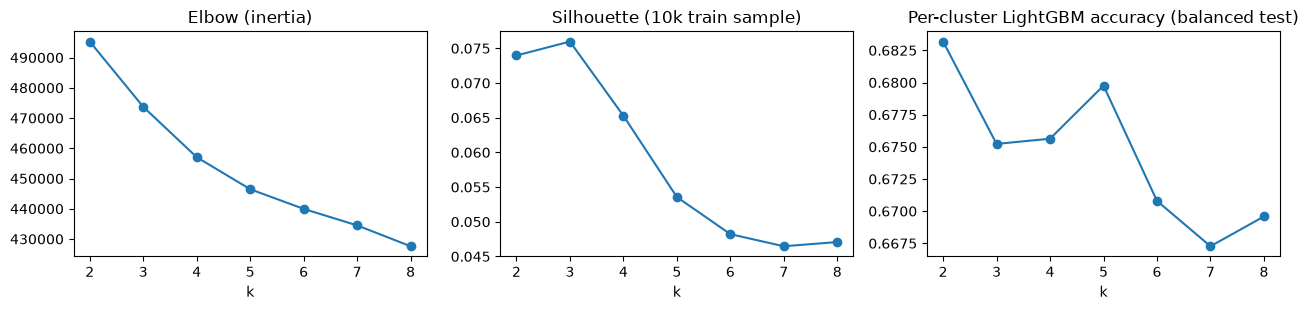

In [20]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, silhouette_score


def fit_per_cluster(kmodel):
    # one LightGBM per cluster on the balanced train rows of that cluster
    cl = kmodel.labels_
    return {c: fit_lgbm(X_train_bal[cl == c], y_train_bal[cl == c]) for c in range(kmodel.n_clusters)}


def predict_per_cluster(kmodel, models, Xs):
    # assign rows to clusters with the fitted k-means, then score each row with its cluster's model
    cl = kmodel.predict(Xs.to_numpy())
    prob = np.zeros(len(Xs))
    for c, m in models.items():
        if (cl == c).any():
            prob[cl == c] = m.predict_proba(Xs[cl == c])[:, 1]
    return cl, prob


Xkm = X_train_bal.to_numpy()
sil_idx = np.random.default_rng(CONFIG["seed"]).choice(len(Xkm), 10000, replace=False)   # silhouette is O(n^2)
km = {}
rows = []
for k in range(2, 9):
    km[k] = KMeans(k, n_init=3, random_state=CONFIG["seed"]).fit(Xkm)
    _, prob = predict_per_cluster(km[k], fit_per_cluster(km[k]), X_test_bal)
    rows.append({"k": k, "inertia": km[k].inertia_,
                 "silhouette": silhouette_score(Xkm[sil_idx], km[k].labels_[sil_idx]),
                 "accuracy": accuracy_score(y_test_bal, prob > 0.5)})
ksel = pd.DataFrame(rows).set_index("k")
print(ksel.round(4))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ksel["inertia"].plot(marker="o", ax=ax[0], title="Elbow (inertia)")
ksel["silhouette"].plot(marker="o", ax=ax[1], title="Silhouette (10k train sample)")
ksel["accuracy"].plot(marker="o", ax=ax[2], title="Per-cluster LightGBM accuracy (balanced test)")
plt.tight_layout(); plt.savefig(OUT / "kmeans_selection.png", dpi=130); plt.show()

In [21]:
K = 4   # the paper's choice; compare with the selection table above before changing
km_final = km[K]
joblib.dump(km_final, OUT / "kmeans.joblib")
c_train = km_final.predict(X_train_s.to_numpy())   # every train row, for the saved assignments and the plots
c_test = km_final.predict(X_test_s.to_numpy())     # never refit on test

pd.concat([
    pd.DataFrame({"SK_ID_CURR": ids.loc[X_train_s.index].to_numpy(), "split": "train", "cluster": c_train}),
    pd.DataFrame({"SK_ID_CURR": ids.loc[X_test_s.index].to_numpy(), "split": "test", "cluster": c_test}),
]).to_csv(OUT / "cluster_assignments.csv", index=False)

# class balance inside each cluster: balanced train/test (used for the models) and all train rows
c_train_bal, c_test_bal = km_final.labels_, km_final.predict(X_test_bal.to_numpy())
bal = pd.DataFrame({
    "n_train_bal": pd.Series(c_train_bal).value_counts().sort_index(),
    "pos_rate_train_bal": pd.Series(y_train_bal.to_numpy()).groupby(c_train_bal).mean(),
    "n_test_bal": pd.Series(c_test_bal).value_counts().sort_index(),
    "pos_rate_test_bal": pd.Series(y_test_bal.to_numpy()).groupby(c_test_bal).mean(),
    "n_train_all": pd.Series(c_train).value_counts().sort_index(),
    "pos_rate_train_all": pd.Series(y_train.to_numpy()).groupby(c_train).mean(),
})
bal.round(4)

,n_train_bal,pos_rate_train_bal,n_test_bal,pos_rate_test_bal,n_train_all,pos_rate_train_all
0,5795,0.3910,1483,0.4005,42845,0.0529
1,10054,0.5274,2513,0.5344,58067,0.0913
2,11010,0.4514,2639,0.4286,73575,0.0676
3,12861,0.5693,3295,0.5757,71521,0.1024


In [22]:
# one LightGBM per cluster against a single LightGBM on the same balanced train rows
models = fit_per_cluster(km_final)
single = fit_lgbm(X_train_bal, y_train_bal)

def table_iv(Xs, ys):
    cl, prob = predict_per_cluster(km_final, models, Xs)
    pred = (prob > 0.5).astype(int)
    out = {f"Cluster {c + 1}": metrics(ys[cl == c], pred[cl == c]) for c in range(K)}
    out["Overall"] = metrics(ys, pred)
    out["Single model, no clustering"] = metrics(ys, single.predict(Xs))
    t = pd.DataFrame(out).T
    return pd.DataFrame({"Accuracy": t["accuracy"], "Precision (0/1)": t["prec_0"].round(2).astype(str) + "/" + t["prec_1"].round(2).astype(str),
                         "Recall (0/1)": t["rec_0"].round(2).astype(str) + "/" + t["rec_1"].round(2).astype(str),
                         "F1 (0/1)": t["f1_0"].round(2).astype(str) + "/" + t["f1_1"].round(2).astype(str),
                         "n": t["n"].astype(int)})

print("Table IV, balanced test (paper protocol)"); display(table_iv(X_test_bal, y_test_bal))
print("Table IV, natural-ratio test"); display(table_iv(X_test_s, y_test))

Table IV, balanced test (paper protocol)


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),n
Cluster 1,0.674309,0.69/0.63,0.83/0.44,0.75/0.52,1483
Cluster 2,0.662953,0.65/0.67,0.59/0.72,0.62/0.7,2513
Cluster 3,0.676393,0.71/0.63,0.74/0.59,0.72/0.61,2639
Cluster 4,0.685281,0.65/0.71,0.56/0.78,0.6/0.74,3295
Overall,0.675629,0.68/0.67,0.67/0.68,0.67/0.68,9930
"Single model, no clustering",0.687714,0.69/0.69,0.68/0.69,0.69/0.69,9930


Table IV, natural-ratio test


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),n
Cluster 1,0.801722,0.96/0.13,0.82/0.44,0.89/0.2,10919
Cluster 2,0.628888,0.96/0.16,0.62/0.72,0.75/0.27,14435
Cluster 3,0.727839,0.96/0.13,0.74/0.59,0.84/0.21,18287
Cluster 4,0.579162,0.95/0.17,0.56/0.78,0.7/0.28,17862
Overall,0.674552,0.96/0.15,0.67/0.68,0.79/0.25,61503
"Single model, no clustering",0.688844,0.96/0.16,0.69/0.69,0.8/0.26,61503


In [23]:
# the paper reports positive-class precision 1.00 everywhere; check what we get from the raw confusion matrices (balanced test)
cl, prob = predict_per_cluster(km_final, models, X_test_bal)
for c in range(K):
    tn, fp, fn, tp = confusion_matrix(y_test_bal[cl == c], prob[cl == c] > 0.5, labels=[0, 1]).ravel()
    print(f"cluster {c + 1}: TN={tn} FP={fp} FN={fn} TP={tp}  precision_1={tp / max(tp + fp, 1):.2f}")

cluster 1: TN=736 FP=153 FN=330 TP=264  precision_1=0.63
cluster 2: TN=696 FP=474 FN=373 TP=970  precision_1=0.67
cluster 3: TN=1119 FP=389 FN=465 TP=666  precision_1=0.63
cluster 4: TN=781 FP=617 FN=420 TP=1477  precision_1=0.71


**Findings.** Silhouette is low and nearly flat for k = 2 to 4 (0.074, 0.076, 0.065) and falls to about 0.047 by k = 8; the elbow curve has no clear bend. By the paper's own criterion, overall accuracy of the per-cluster models, k = 2 is best (0.683) and k = 4 gives 0.676, so k = 4 is not reproduced as best under either criterion. K = 4 is kept only to follow the paper.

Clustering does not help here. The four per-cluster models reach 0.676 overall on the balanced test against 0.688 for a single LightGBM on the same rows; every k from 2 to 8 is below the single model. The paper reports a gain from 57.5% to 71.6%, but its two numbers come from different LightGBM settings and training sets. Per-cluster accuracy is 0.66 to 0.69, without the paper's 82% cluster.

Cluster 1 is the pensioner group (the `DAYS_EMPLOYED` placeholder flag is set for all of its rows) and has the lowest default rate, 5.3% over all train rows against 6.8% to 10.2% in the others. No cluster is close to pure.

Positive-class precision is 0.63 to 0.71 on the balanced test and 0.13 to 0.17 at the natural ratio, with 153 to 617 false positives per cluster, so the paper's 1.00 positive precision (with 1.00 negative recall) is not reproduced. The same pattern appears in the authors' own notebook output for random forest, LightGBM and MLP but not for logistic regression, and its cause is not visible in their published code, so we treat that column of Table IV as unreliable.

## 8. PCA and t-SNE visualisations (Figure 2)

In [24]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Xtr = X_train_s.to_numpy()
pca = PCA(n_components=50, random_state=CONFIG["seed"]).fit(Xtr)
Z = pca.transform(Xtr)
evr = pca.explained_variance_ratio_
print(f"variance explained by PC1+PC2: {evr[:2].sum():.1%} (paper: ~23%; the authors' own full-data run prints 14.7%); first 50 components: {evr.sum():.1%}")

# t-SNE on a random subsample of train
sub = np.random.default_rng(CONFIG["seed"]).choice(len(Xtr), 8000, replace=False)
ysub, csub = y_train.to_numpy()[sub], c_train[sub]
tsne_raw = TSNE(2, perplexity=30, init="pca", random_state=CONFIG["seed"], n_jobs=-1).fit_transform(Xtr[sub])
tsne_pca = TSNE(2, perplexity=30, init="pca", random_state=CONFIG["seed"], n_jobs=-1).fit_transform(Z[sub])

variance explained by PC1+PC2: 17.7% (paper: ~23%; the authors' own full-data run prints 14.7%); first 50 components: 80.3%


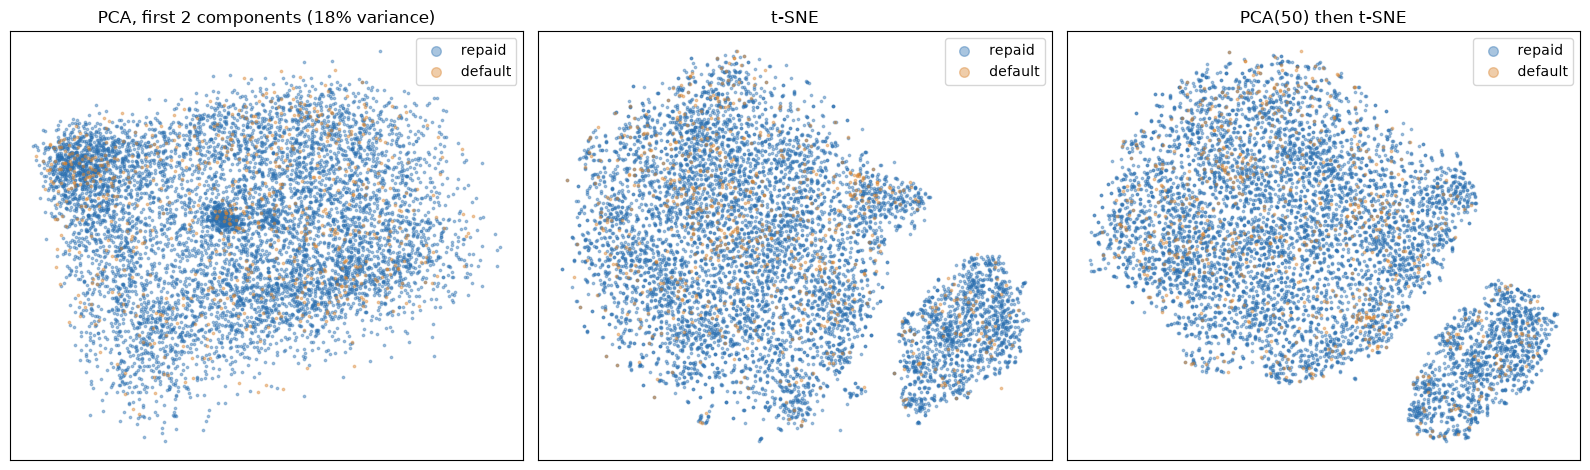

In [25]:
def scatter(ax, P, labels, title, palette, names):
    for lab, col in palette.items():
        m = labels == lab
        ax.scatter(P[m, 0], P[m, 1], s=3, alpha=0.4, c=col, label=names[lab], rasterized=True)
    ax.set_title(title); ax.legend(markerscale=4, loc="best")

cls_pal, cls_names = {0: "#2a6fb0", 1: "#d9822b"}, {0: "repaid", 1: "default"}
pcs = Z[sub, :2]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
scatter(ax[0], pcs, ysub, f"PCA, first 2 components ({evr[:2].sum():.0%} variance)", cls_pal, cls_names)
scatter(ax[1], tsne_raw, ysub, "t-SNE", cls_pal, cls_names)
scatter(ax[2], tsne_pca, ysub, "PCA(50) then t-SNE", cls_pal, cls_names)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(OUT / "figure2.png", dpi=150); plt.show()

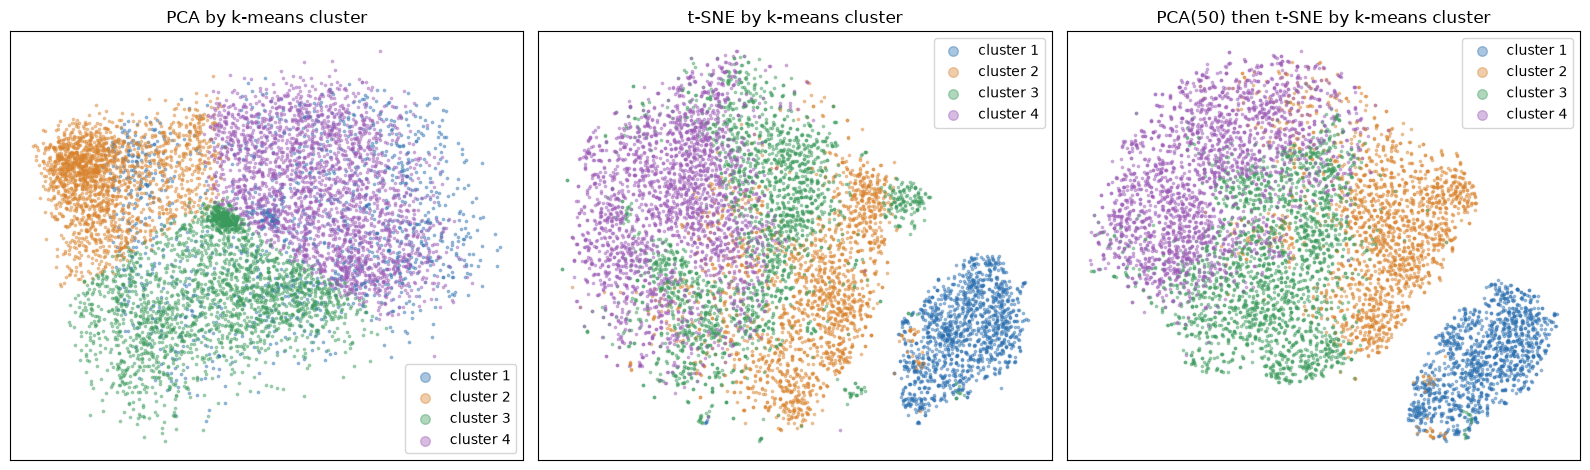

In [26]:
# same embeddings coloured by k-means cluster, to check for the four visible clusters
cl_pal = dict(zip(range(K), ["#2a6fb0", "#d9822b", "#3a9a5b", "#9b59b6"]))
cl_names = {c: f"cluster {c + 1}" for c in range(K)}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, P, t in zip(ax, (pcs, tsne_raw, tsne_pca), ("PCA", "t-SNE", "PCA(50) then t-SNE")):
    scatter(a, P, csub, t + " by k-means cluster", cl_pal, cl_names); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(OUT / "figure2_clusters.png", dpi=150); plt.show()

**Findings.** PC1+PC2 explain 17.7% of the variance and 50 components explain 80.3%. The paper quotes about 23%, but the authors' own full-data PCA prints 8.2% + 6.5% = 14.7%; the larger figure comes from a 10,000-row subset whose input still contained the three principal-component score columns and the label. The classes overlap almost completely in all three views, matching the paper's main qualitative finding.

The PCA plane shows one connected cloud with a few denser patches, not four separated groups. t-SNE shows one clearly separate island, which is k-means cluster 1 (the pensioners); the other three clusters are adjacent regions of the main cloud. The paper's four separated PCA groups (pensioner or not, by gender) do appear when the `previous_application` aggregates are also left out, as in the authors' code (checked separately); with them included the binary application columns no longer dominate the first two components.

## Notes on differences from the paper

Changes made to follow the paper and the authors' code: `EXT_SOURCE_1..3` are excluded, features are min-max scaled to [0, 1], models are trained on a down-sampled train set and tested on a balanced test set, k-means is fitted on the balanced train set, and per-cluster models are not rebalanced.

- **Features:** 832 joined columns, 700 features after the `EXT_SOURCE` drop, the 30% missing-value drop and encoding. The paper's 217 is the sum of the raw column counts in its Table I, not the width of a joined table; its final matrix has 651 columns. Credit-card aggregates are almost all dropped by the 30% rule because only about a third of clients have card history; only `cc_COUNT` survives (counts of records are set to 0 for clients with no history).
- **previous_application:** we aggregate it (354 of the 700 features) because the paper lists it in Table I; the authors' code never reads it. This is the main remaining difference in the feature set.
- **Missing values:** mean imputation keeps all 307,511 rows. Dropping rows would keep 48.3% of them here (paper Table II: 33%). The authors' training run median-imputes and keeps all 307,511 rows, so the 102,244 figure does not describe the data their models were trained on. LightGBM AUC is 0.762 with imputation against 0.752 after dropping rows.
- **Scaling:** our scaler, imputer and column drop are fitted on the train split only; the authors fit theirs on all rows before splitting.
- **Balancing:** see section 5. SMOTE is not usable with tree models on this table.
- **Models:** LightGBM with 300 trees and learning rate 0.05, threshold 0.5. The authors' Table IV run uses 10,000 trees at learning rate 0.02 without early stopping and reports precision and recall at P(default) > 0.4.
- **Clustering:** k = 4 is not reproduced as best and clustering gives no gain over a single model (0.676 against 0.688); see section 7.
- **Table IV:** positive-class precision 1.00 is not reproduced (0.63 to 0.71 balanced, 0.13 to 0.17 natural).
- **PCA:** 17.7% of variance in two components; the paper's 23% is inflated, see above.
- **Polynomial features:** top-20 degree-2 terms add +0.004 AUC to logistic regression (0.744 to 0.748). That logistic regression stops at the 300-iteration limit, so its numbers are approximate.